In [1]:
import os
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

from torch import nn, optim
from torch.utils.data import DataLoader

from torchvision import transforms, datasets

import kornia.augmentation as K

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_class_weight


In [2]:

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
train_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/train"

val_path = r"/kaggle/input/datasets/bmuthukumar07/seed-data/data/val"

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
train_set = datasets.ImageFolder(
    root = train_path,
    transform = train_transform
)

test_set = datasets.ImageFolder(
    root = val_path,
    transform = test_transform
)

classes = train_set.classes
num_classes = len(classes)


In [6]:
train_count = Counter(train_set.targets)
test_count = Counter(test_set.targets)

print("=" * 55)
print("Dataset Distribution")
print("=" * 55)

for i, cls in enumerate(classes):
    print(
        f"{cls:<15}"
        f"Train: {train_count[i]:5}"
        f" | Val: {test_count[i]:5}"
    )

print("=" * 55)
print(f"Total Train Images : {len(train_set)}")
print(f"Total Val Images   : {len(test_set)}")

Dataset Distribution
broken         Train:  4554 | Val:  1116
discolored     Train:  2504 | Val:   611
pure           Train:  5855 | Val:  1428
silkcut        Train:  1427 | Val:   324
Total Train Images : 14340
Total Val Images   : 3479


In [7]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_set,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 4,
    pin_memory = True,
    persistent_workers = True
)

test_loader = DataLoader(
    test_set,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 4,
    pin_memory = True,
    persistent_workers = True
)

In [8]:
gpu_aug = nn.Sequential(

    K.RandomResizedCrop(
        size=(224, 224),
        scale=(0.75,1.0),
        ratio=(0.8,1.2)
    ),

    K.RandomHorizontalFlip(p=0.5),

    K.RandomRotation(
        degrees=20,
        p=0.5
    ),

    K.RandomAffine(
        degrees=0,
        translate=(0.1,0.1),
        scale=(0.9,1.1),
        p=0.5
    ),

    K.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.3,
        hue=0.05,
        p=0.6
    ),

    K.RandomGaussianBlur(
        kernel_size=(3,3),
        sigma=(0.1,2.0),
        p=0.2
    ),

    K.RandomSharpness(
        sharpness=0.4,
        p=0.2
    ),

    K.Normalize(
        mean=torch.tensor([0.485,0.456,0.406]),
        std=torch.tensor([0.229,0.224,0.225])
    )

).to(device)

In [9]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.DEFAULT
base_model = resnet50(weights=weights)

for param in base_model.conv1.parameters():
    param.requires_grad = False

for param in base_model.bn1.parameters():
    param.requires_grad = False

for param in base_model.layer1.parameters():
    param.requires_grad = False

num_features = base_model.fc.in_features

base_model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.BatchNorm1d(256),
    nn.Dropout(0.3),
    nn.Linear(256, len(classes))
)

model = base_model.to(device)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

non_trainable_params = total_params - trainable_params

print(f"Trainable Parameters : {trainable_params:,}")
print(f"Non Trainable Parameters : {non_trainable_params:,}")
print(f"Total Parameters : {total_params:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 162MB/s] 


Trainable Parameters : 23,808,772
Non Trainable Parameters : 225,344
Total Parameters : 24,034,116


In [10]:
criterion = nn.CrossEntropyLoss(
    label_smoothing = 0.05
)

optimizer = optim.AdamW(
    [
        {
            "params": [
                *base_model.conv1.parameters(),
                *base_model.bn1.parameters(),
                *base_model.layer1.parameters(),
                *base_model.layer2.parameters(),
                *base_model.layer3.parameters(),
                *base_model.layer4.parameters(),
            ],
            "lr": 5e-5,
        },
        {
            "params": base_model.fc.parameters(),
            "lr": 5e-4,
        },
    ],
    weight_decay=0.05
)

epochs = 40

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=5,
    T_mult=2,
    eta_min=1e-6
)

In [11]:
scaler = torch.amp.GradScaler("cuda")
train_acc_history = []
val_acc_history = []

train_loss_history = []
val_loss_history = []

best_accuracy = 0.0
best_val_loss = float("inf")

patience = 10
counter = 0

for epoch in range(epochs):

    start_time = time.time()

    # -------------------- TRAINING --------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        images = gpu_aug(images)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total
    train_loss = running_loss / len(train_loader)

    train_acc_history.append(train_acc)
    train_loss_history.append(train_loss)

    # ---------------- VALIDATION ----------------

    model.eval()

    correct = 0
    total = 0
    val_running_loss = 0.0

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast("cuda"):

                outputs = model(images)

                loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_acc = correct / total
    val_loss = val_running_loss / len(test_loader)

    val_acc_history.append(val_acc)
    val_loss_history.append(val_loss)

    scheduler.step()

    if val_acc > best_accuracy:
        best_val_loss = val_loss
        best_accuracy = val_acc
        torch.save(model.state_dict(),"/kaggle/working/best_mobilenet_v2.pth")
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    elapsed_time = time.time() - start_time
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Acc: {train_acc:.4f} "
        f"Val Acc: {val_acc:.4f} "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Time: {elapsed_time/60:.2f} min"
    )

print(f"\nBest Validation Loss : {best_val_loss:.4f}")
print(f"Best Validation Accuracy : {best_accuracy:.4f}")

Epoch [1/40] Train Acc: 0.6075 Val Acc: 0.7037 Train Loss: 1.0171 Val Loss: 0.8204 Time: 1.39 min
Epoch [2/40] Train Acc: 0.7225 Val Acc: 0.7623 Train Loss: 0.7855 Val Loss: 0.7113 Time: 1.12 min
Epoch [3/40] Train Acc: 0.7662 Val Acc: 0.7637 Train Loss: 0.6985 Val Loss: 0.6894 Time: 1.11 min
Epoch [4/40] Train Acc: 0.7857 Val Acc: 0.7723 Train Loss: 0.6546 Val Loss: 0.6769 Time: 1.11 min
Epoch [5/40] Train Acc: 0.8021 Val Acc: 0.7795 Train Loss: 0.6252 Val Loss: 0.6666 Time: 1.11 min
Epoch [6/40] Train Acc: 0.7865 Val Acc: 0.7611 Train Loss: 0.6561 Val Loss: 0.7025 Time: 1.10 min
Epoch [7/40] Train Acc: 0.7948 Val Acc: 0.7654 Train Loss: 0.6381 Val Loss: 0.7034 Time: 1.10 min
Epoch [8/40] Train Acc: 0.8158 Val Acc: 0.7660 Train Loss: 0.5992 Val Loss: 0.6910 Time: 1.11 min
Epoch [9/40] Train Acc: 0.8282 Val Acc: 0.7732 Train Loss: 0.5687 Val Loss: 0.6916 Time: 1.11 min
Epoch [10/40] Train Acc: 0.8480 Val Acc: 0.7600 Train Loss: 0.5333 Val Loss: 0.7243 Time: 1.10 min
Epoch [11/40] Train

In [12]:
print("\nAccuracy:",
      accuracy_score(y_true, y_pred))

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)

print(confusion_matrix(
    y_true,
    y_pred
))


Accuracy: 0.7680367921816614
              precision    recall  f1-score   support

      broken       0.72      0.78      0.75      1116
  discolored       0.67      0.62      0.64       611
        pure       0.85      0.82      0.84      1428
     silkcut       0.75      0.76      0.75       324

    accuracy                           0.77      3479
   macro avg       0.75      0.74      0.75      3479
weighted avg       0.77      0.77      0.77      3479

[[ 876   90  122   28]
 [ 138  376   67   30]
 [ 168   61 1175   24]
 [  31   32   16  245]]


In [14]:
# Load saved weights
WEIGHTS_PATH = "//kaggle/working/best_resnet_50.pth"

model.load_state_dict(
    torch.load(
        WEIGHTS_PATH,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Saved weights loaded successfully!")

Saved weights loaded successfully!


In [17]:
%pip install -q grad-cam shap lime captum scikit-learn seaborn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from skimage.segmentation import mark_boundaries

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

from captum.attr import IntegratedGradients, Occlusion
import shap
from lime import lime_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 695.2 kB/s eta 0:00:00 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 3.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [18]:
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = F.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

if "class_names" not in globals():
    class_names = test_loader.dataset.classes

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Test samples:", len(all_labels))

Classes: ['broken', 'discolored', 'pure', 'silkcut']
Number of classes: 4
Test samples: 3479


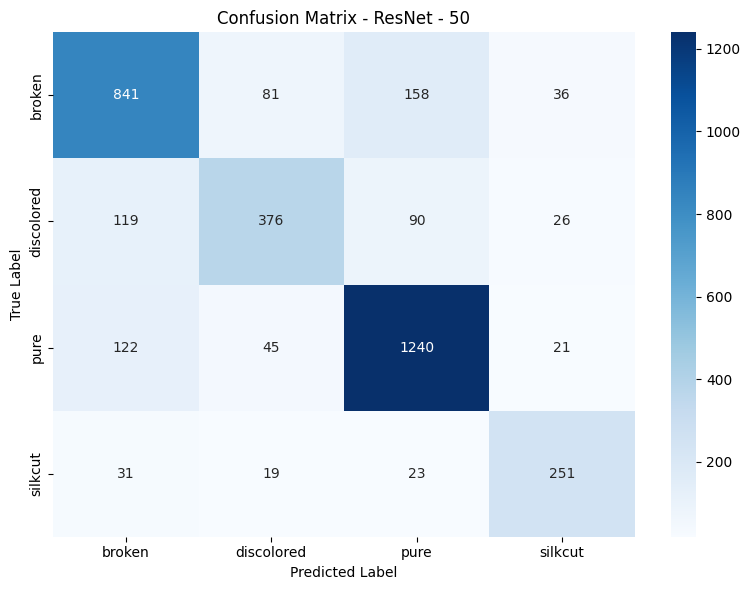

In [19]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - ResNet - 50")
plt.tight_layout()
plt.show()

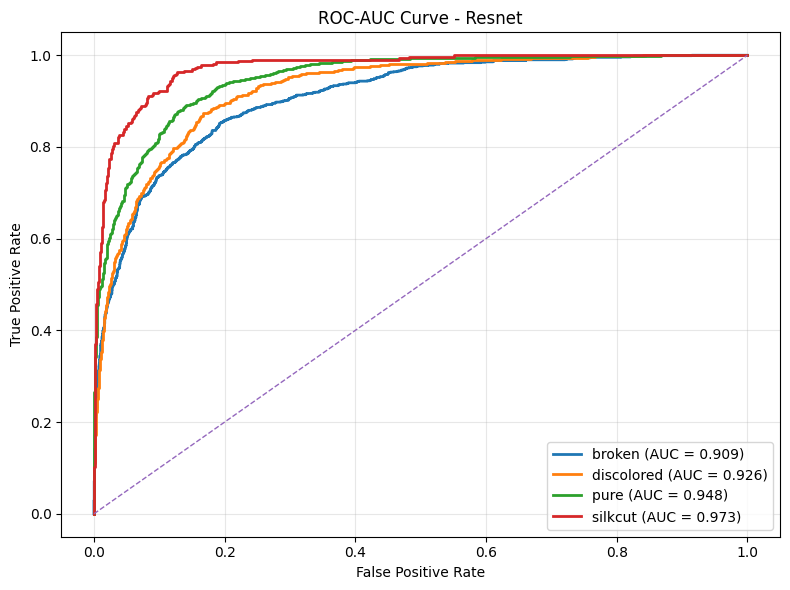

In [20]:
y_true_onehot = np.eye(num_classes)[all_labels]

plt.figure(figsize=(8, 6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Resnet")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

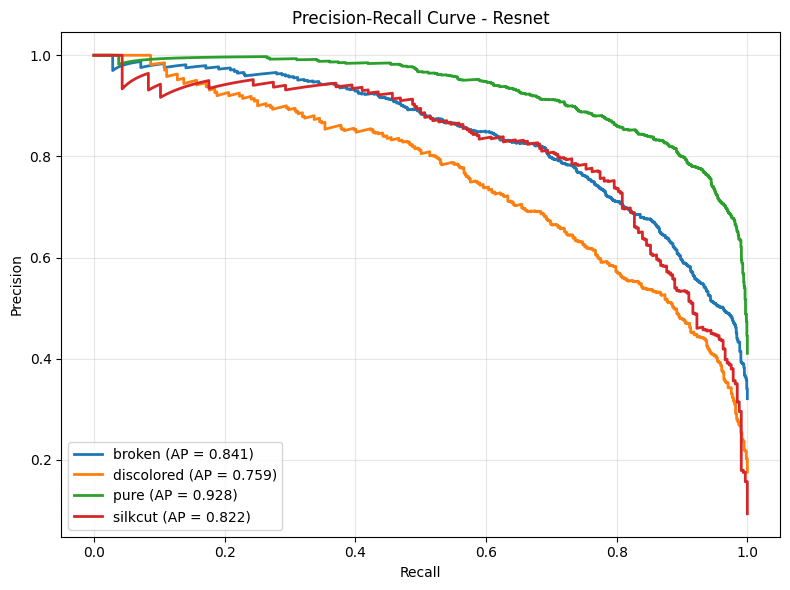

In [22]:
plt.figure(figsize=(8, 6))

for i in range(num_classes):
    precision, recall, _ = precision_recall_curve(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    ap = average_precision_score(
        y_true_onehot[:, i],
        all_probabilities[:, i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{class_names[i]} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Resnet")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
model.eval()

xai_image = None
xai_label = None
xai_prediction = None

for images, labels in test_loader:
    images = images.to(device, non_blocking=True)

    with torch.no_grad():
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

    correct_indices = torch.where(predictions == labels.to(device))[0]

    if len(correct_indices) > 0:
        idx = correct_indices[0].item()

        xai_image = images[idx:idx + 1]
        xai_label = labels[idx].item()
        xai_prediction = predictions[idx].item()
        break

if xai_image is None:
    images, labels = next(iter(test_loader))

    xai_image = images[0:1].to(device)
    xai_label = labels[0].item()

    with torch.no_grad():
        xai_prediction = model(xai_image).argmax(dim=1).item()

print("True class:", class_names[xai_label])
print("Predicted class:", class_names[xai_prediction])

True class: broken
Predicted class: broken


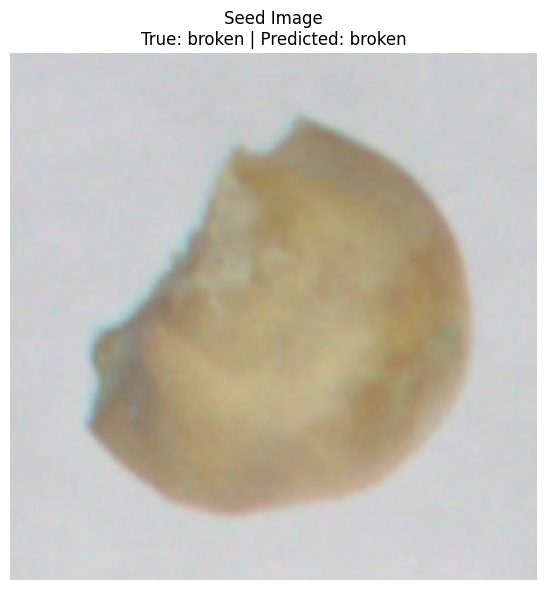

In [24]:

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = (
    xai_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

# Properly undo ImageNet normalization
image_display = (
    image_display * std
) + mean

image_display = np.clip(
    image_display,
    0,
    1
)

plt.figure(figsize=(6, 6))

plt.imshow(image_display)

plt.axis("off")

plt.title(
    f"Seed Image\n"
    f"True: {class_names[xai_label]} | "
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

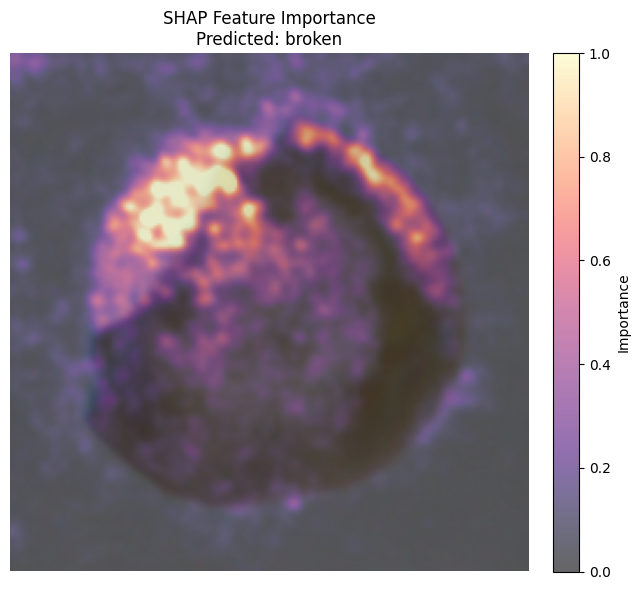

In [25]:
model.eval()

background = next(iter(test_loader))[0][:2].to(device)

class SHAPTargetModel(nn.Module):

    def __init__(self, model, target_class):
        super().__init__()
        self.model = model
        self.target_class = target_class

    def forward(self, x):
        output = self.model(x)

        return output[
            :,
            self.target_class:self.target_class + 1
        ]


shap_model = SHAPTargetModel(
    model,
    xai_prediction
).to(device)

explainer = shap.GradientExplainer(
    shap_model,
    background
)

shap_values = explainer.shap_values(
    xai_image
)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

# Remove unnecessary dimensions
shap_values = np.squeeze(shap_values)

if shap_values.ndim == 3:

    if shap_values.shape[0] in [1, 3]:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=0
        )
    else:
        shap_map = np.mean(
            np.abs(shap_values),
            axis=-1
        )

# Smooth pixel-level noise
shap_map = gaussian_filter(
    shap_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    shap_map,
    5
)

high = np.percentile(
    shap_map,
    99
)

shap_map = np.clip(
    (shap_map - low) / (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    shap_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"SHAP Feature Importance\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

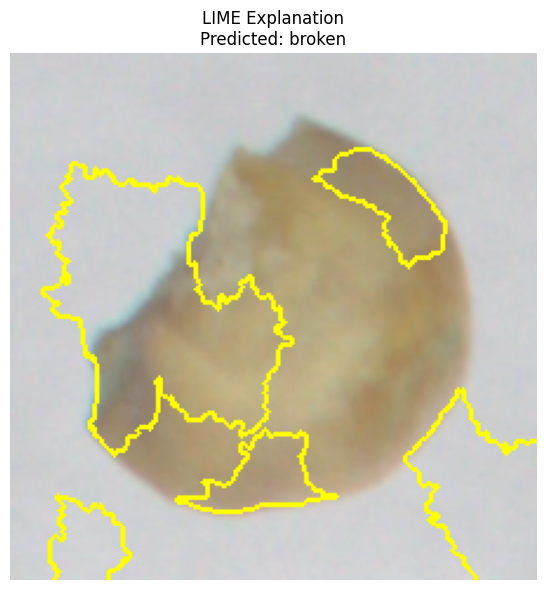

In [26]:
# ============================================================
# IMPROVED LIME
# ============================================================

def lime_predict(images):

    batch = []

    for image in images:

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        image = image.permute(
            2, 0, 1
        )

        image = image / 255.0

        image = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )(image)

        batch.append(image)

    batch = torch.stack(batch).to(device)

    with torch.no_grad():

        outputs = model(batch)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

    return probabilities.cpu().numpy()


lime_explainer = lime_image.LimeImageExplainer(
    verbose=False
)

lime_input = (
    image_display * 255
).astype(np.uint8)

lime_result = lime_explainer.explain_instance(
    lime_input,
    lime_predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

lime_label = lime_result.top_labels[0]

lime_result_image, lime_mask = (
    lime_result.get_image_and_mask(
        lime_label,
        positive_only=True,
        num_features=8,
        hide_rest=False
    )
)

# Create clean boundary visualization
lime_boundary = mark_boundaries(
    lime_result_image,
    lime_mask,
    color=(1, 1, 0),
    mode="thick"
)

plt.figure(figsize=(7, 6))

plt.imshow(
    lime_boundary
)

plt.axis("off")

plt.title(
    f"LIME Explanation\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.tight_layout()
plt.show()

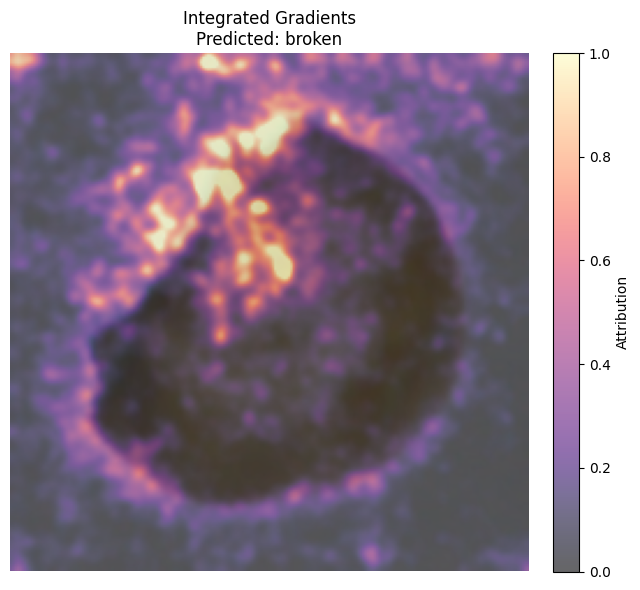

In [27]:


model.eval()

ig = IntegratedGradients(model)

baseline = torch.zeros_like(
    xai_image
)

ig_attributions = ig.attribute(
    xai_image,
    baselines=baseline,
    target=xai_prediction,
    n_steps=64
)

ig_map = (
    ig_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

# Channel aggregation
ig_map = np.mean(
    np.abs(ig_map),
    axis=0
)

# Remove high-frequency noise
ig_map = gaussian_filter(
    ig_map,
    sigma=2
)

# Robust normalization
low = np.percentile(
    ig_map,
    5
)

high = np.percentile(
    ig_map,
    99
)

ig_map = np.clip(
    (ig_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    ig_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Integrated Gradients\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Attribution"
)

plt.tight_layout()
plt.show()

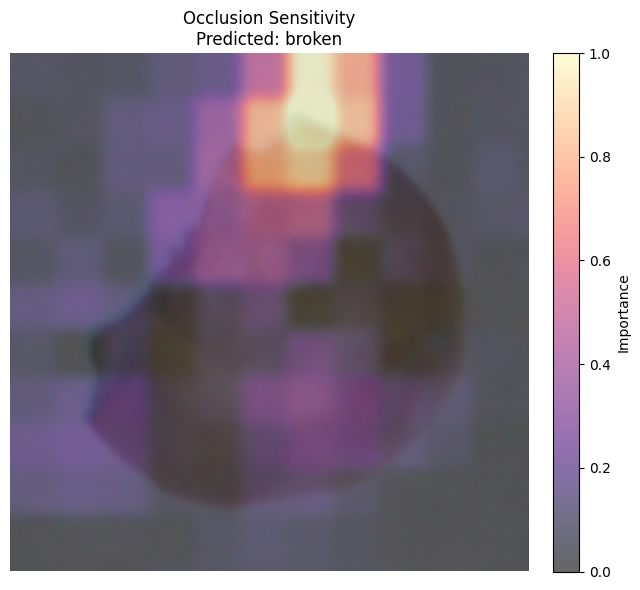

In [28]:
# ============================================================
# IMPROVED OCCLUSION SENSITIVITY
# ============================================================

model.eval()

occlusion = Occlusion(model)

occlusion_attributions = occlusion.attribute(
    xai_image,
    target=xai_prediction,
    strides=(3, 20, 20),
    sliding_window_shapes=(3, 40, 40),
    baselines=0
)

occlusion_map = (
    occlusion_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

occlusion_map = np.mean(
    np.abs(occlusion_map),
    axis=0
)

# Smooth the grid effect
occlusion_map = gaussian_filter(
    occlusion_map,
    sigma=3
)

# Robust normalization
low = np.percentile(
    occlusion_map,
    5
)

high = np.percentile(
    occlusion_map,
    99
)

occlusion_map = np.clip(
    (occlusion_map - low) /
    (high - low + 1e-8),
    0,
    1
)

plt.figure(figsize=(7, 6))

plt.imshow(
    image_display
)

plt.imshow(
    occlusion_map,
    cmap="magma",
    alpha=0.60,
    vmin=0,
    vmax=1
)

plt.axis("off")

plt.title(
    f"Occlusion Sensitivity\n"
    f"Predicted: {class_names[xai_prediction]}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Importance"
)

plt.tight_layout()
plt.show()